# 05 · Out-of-sample backtest: execution simulator on the recorded order book

Every strategy liquidates the **same orders on the same windows** of the 4 test days. Strategies only know parameters estimated on
**earlier days**; the simulator judges them on the **test day's own market**.

**Simulator**
* A strategy's slice for each decision interval is sent as child market orders every ~2 s.
* Each child **walks the recorded bid book** at that second (top 100 levels, 1-second snapshots) → spread + depth cost.
* The recorded book never reacted to our orders, so the whole book is shifted down by **our own accumulated impact**:
  `I(t) = Σ_past children  H(t − t_j) · q_j`, with the impact kernel `H` **fitted on the test day itself** (unknown to the strategies).
* Cost = **implementation shortfall** vs the arrival mid, split into market drift, our impact and book walk.

**Strategies:** TWAP · forecast-VWAP · POV (fixed share of the previous interval's real volume) · immediate ·
AC heuristic · AC calibrated · optimal transient (each at several risk aversions λ).

**Impact scenarios (robustness):** `test_day_kernel` (default) · `calib_kernel` (the optimizer's own model — circular, shown for transparency) ·
`sqrt_law` (permanent impact follows the square-root law) · `impact_x2` (all impact doubled).

**Edit only the CONFIG cell, then Run All.** Needs the day folders (notebook 01) and `analysis/ETHUSDT` (notebooks 02–04).

In [17]:
# ============================== CONFIG — edit this cell only ==============================
import os
ROOT    = r"C:\Users\Nitish Singh\OneDrive\Desktop\ope_daywise"
SYMBOL  = "ETHUSDT"
ANALYSIS_DIR = os.path.join(ROOT, "analysis", SYMBOL)

LAMBDAS_OOS = (0.0, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1)   # risk aversions for the optimizers (1/bps); λ=0 anchors the frontier at the TWAP end
REF_LAMBDA  = 0.01                                # λ used in headline tables
SCENARIOS   = ("test_day_kernel", "calib_kernel", "sqrt_law", "impact_x2")
SQRT_Y      = 1.0                                 # square-root law prefactor (literature: ~0.5–1)
CHILD_EVERY_S = 2                                 # target spacing of child orders (s)
N_BOOT      = 1000
MIN_SECONDS_USABLE = 0.99                         # a window is simulated only if its arrival second is usable and >= 99% of its seconds are                              # bootstrap resamples (clusters = test day × start hour)
MAX_WINDOWS = None                                # e.g. 300 for a quick trial run; None = all windows
# =========================================================================================

In [18]:
import glob, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
WALK_GRID = np.logspace(-2, np.log10(60000), 72)
A_DIR = Path(ANALYSIS_DIR)
for f in ["impact_params.json", "executions.parquet", "volume_curve_forecasts.parquet", "split.json",
          "immediate_cost_curve.csv", "optimizer_config.json", "summary.json"]:
    assert (A_DIR / f).exists(), f"missing {f}: run notebooks 02-04 first"
PARAMS = json.load(open(A_DIR / "impact_params.json"))
OPTCFG = json.load(open(A_DIR / "optimizer_config.json"))
EX = pd.read_parquet(A_DIR / "executions.parquet")
VC = pd.read_parquet(A_DIR / "volume_curve_forecasts.parquet")
IC = pd.read_csv(A_DIR / "immediate_cost_curve.csv")
TEST_DATES = list(PARAMS)
found = {}
for qs in sorted(glob.glob(os.path.join(ROOT, "**", "clean", SYMBOL, "*", "qc_summary.json"), recursive=True)):
    found.setdefault(os.path.basename(os.path.dirname(qs)), os.path.dirname(qs))
MIN_STEP_S, MAX_STEPS, KERNEL = OPTCFG["MIN_STEP_S"], OPTCFG["MAX_STEPS"], OPTCFG["KERNEL"]
COL = {"optimal_transient": "#2f6fdf", "ac_calibrated": "#e07b39", "ac_heuristic": "#8c6bb1", "twap": "#4b5563",
       "vwap": "#3a9a5b", "pov": "#c2410c", "immediate": "#a3a3a3"}
def style(ax, title):
    ax.set_title(title, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e6e8eb", lw=0.8)
if MAX_WINDOWS:
    keep = EX[["test_date", "start_min", "horizon_min"]].drop_duplicates().sample(MAX_WINDOWS, random_state=0)
    EX = EX.merge(keep, on=["test_date", "start_min", "horizon_min"])
print(f"test days {TEST_DATES} | {len(EX):,} orders on {EX[['test_date','start_min','horizon_min']].drop_duplicates().shape[0]:,} windows")

test days ['2026-09-11', '2026-09-12', '2026-09-13', '2026-09-14'] | 4,668 orders on 1,695 windows


## 1 · Strategy schedules (same optimizer code as notebook 04, parameters from calibration days only)

In [19]:
def proj_simplex(v, X):
    u = np.sort(v)[::-1]; css = np.cumsum(u) - X
    ind = np.arange(1, len(v) + 1); cond = u - css / ind > 0
    rho = ind[cond][-1]; theta = css[cond][-1] / rho
    return np.maximum(v - theta, 0.0)

def objective(n, Q, X, s2dt, lam, imm):
    h, a, b, m = imm
    x = X - np.cumsum(n); npos = np.maximum(n, 0.0)
    quad = 0.5 * n @ Q @ n
    walk = (n * h + a * npos * (npos / m) ** b).sum() if a > 0 else (n * h).sum()
    var = s2dt * (x ** 2).sum()
    return quad + walk + lam * var, quad, walk, var

def solve(Q, X, s2dt, lam, imm=(0.0, 0.0, 1.0, 1.0), n0=None, iters=4000, tol=1e-10):
    N = Q.shape[0]; h, a, b, m = imm
    def grad(n):
        x = X - np.cumsum(n)
        g_risk = -2 * s2dt * lam * np.cumsum(x[::-1])[::-1]
        g_walk = h + (a * (1 + b) * (np.maximum(n, 0) / m) ** b if a > 0 else 0.0)
        return Q @ n + g_walk + g_risk
    f = lambda n: objective(n, Q, X, s2dt, lam, imm)[0]
    n = np.full(N, X / N) if n0 is None else proj_simplex(n0, X)
    y, t, L = n.copy(), 1.0, max(np.abs(Q).sum(1).max() + 2 * s2dt * lam * N, 1e-12)
    f_old = f(n)
    for it in range(iters):
        g = grad(y); fy = f(y)
        for _ in range(60):
            z = proj_simplex(y - g / L, X)
            if f(z) <= fy + g @ (z - y) + 0.5 * L * ((z - y) ** 2).sum() + 1e-12 * max(1.0, abs(fy)): break
            L *= 2.0
        t_new = 0.5 * (1 + np.sqrt(1 + 4 * t * t))
        y = z + (t - 1) / t_new * (z - n)
        f_new = f(z)
        if f_new > f_old: y = z.copy(); t_new = 1.0
        if abs(f_old - f_new) <= tol * max(1.0, abs(f_old)) and it > 50: n = z; break
        n, t, f_old = z, t_new, f_new
        L *= 0.9
    return n

def ac_closed_form(X, N, dt, sigma, lam, gamma, eta):
    eta_t = eta - 0.5 * gamma * dt
    t = dt * np.arange(N + 1); T = N * dt
    if lam <= 0: x = X * (1 - t / T)
    else:
        kappa = np.arccosh(1 + lam * sigma ** 2 * dt ** 2 / (2 * eta_t)) / dt
        x = X * np.sinh(kappa * (T - t)) / np.sinh(kappa * T)
    return x, -np.diff(x)

def fit_walk(half_spread):
    d = IC[(IC.orders >= 50) & (IC.qty_median >= 10)].copy(); d["y"] = d.cost_mean_bps - half_spread; d = d[d.y > 0]
    if len(d) < 3: return 0.0, 1.0
    b, la = np.polyfit(np.log(d.qty_median), np.log(d.y), 1); return float(np.exp(la)), float(max(b, 0.05))

def kernel_H(p, lags_s):
    if KERNEL == "parametric":
        return p["H_inf_bps_per_M"] + p["A_bps_per_M"] * np.exp(-lags_s / p["tau_s"])
    Hm = np.asarray(p["kernel_H_bps_per_M"]); grid = (np.arange(len(Hm)) + 0.5) * p["kernel_bar_s"]
    return np.interp(lags_s, grid, Hm, left=Hm[0], right=Hm[-1])

def grid_for(T_min):
    N = int(min(MAX_STEPS, max(1, round(T_min * 60 / MIN_STEP_S)))); return N, T_min * 60 / N

def make_model(p, X_eth, T_min):
    N, dt = grid_for(T_min); c = p["price_ref"] / 1e6
    M = kernel_H(p, dt * np.abs(np.subtract.outer(np.arange(N), np.arange(N))))
    w, V = np.linalg.eigh(M)
    if w.min() < 0: M = (V * np.maximum(w, 0)) @ V.T
    a, b = fit_walk(p["half_spread_bps"]); m = max(1.0, dt / CHILD_EVERY_S)
    sigma = p["sigma_bps_per_sqrt_s"]
    return dict(N=N, dt=dt, Q=c * X_eth * M, imm=(p["half_spread_bps"], a * X_eth ** b, b, m), s2dt=sigma ** 2 * dt,
                sigma=sigma, gamma=p["gamma_bps_per_ETH"] * X_eth, eta=p["eta_bps_per_ETH_per_s"] * X_eth)

def ac_params_heuristic(p):
    V_day = p["market_volume_ETH_per_s"] * 86400; spread = 2 * p["half_spread_bps"]
    return spread / (0.1 * V_day), spread * 86400 / (0.01 * V_day)

_SCHED = {}
def model_schedules(d, X_eth, T_min):
    # fractions per decision interval for every model-based strategy (cached per test day / size / horizon)
    key = (d, round(X_eth, 6), T_min)
    if key in _SCHED: return _SCHED[key]
    p = PARAMS[d]; out = {}
    N, dt = grid_for(T_min)
    out["twap"] = np.full(N, 1.0 / N)
    out["immediate"] = np.r_[1.0, np.zeros(N - 1)]
    g_h, e_h = ac_params_heuristic(p)
    for lam in LAMBDAS_OOS:
        mdl = make_model(p, X_eth, T_min)
        _, n_ac = ac_closed_form(1.0, N, dt, mdl["sigma"], lam, mdl["gamma"], max(mdl["eta"], 0.5 * mdl["gamma"] * dt * 1.01))
        out[f"ac_calibrated|{lam}"] = n_ac
        _, n_h = ac_closed_form(1.0, N, dt, mdl["sigma"], lam, g_h * X_eth, max(e_h * X_eth, 0.5 * g_h * X_eth * dt * 1.01))
        out[f"ac_heuristic|{lam}"] = n_h
        out[f"optimal_transient|{lam}"] = solve(mdl["Q"], 1.0, mdl["s2dt"], lam, mdl["imm"], n0=n_ac)
    _SCHED[key] = out
    return out

t0 = time.time()
for (d, X_eth, T), _ in EX.groupby(["test_date", "X0_ETH", "horizon_min"]):
    model_schedules(d, X_eth, T)
print(f"{len(_SCHED)} schedule sets ({len(next(iter(_SCHED.values())))} strategies each) in {time.time()-t0:.0f}s")

56 schedule sets (23 strategies each) in 22s


## 2 · Simulator inputs for one test day
* **Book-walk table:** for every second of the day and a grid of child sizes, the cost (bps vs mid) of selling that size into the
  recorded bid book. Sizes beyond the 100 recorded levels are extrapolated at the average depth density of the recorded book.
* **Test-day impact kernel:** the model-free propagator kernel (notebook 03 method) fitted on the test day's own 10-second bars.

In [20]:
LAG_EDGES = (0, 1, 2, 3, 5, 9, 17, 33, 65, 129, 181); BAR_S = 10

def load_day(d):
    f = found[d]; DAY0 = int(pd.Timestamp(d, tz="UTC").value // 1_000_000)
    tick = json.load(open(os.path.join(f, "qc_summary.json")))["l2"]["tick"]
    p1 = pd.read_parquet(os.path.join(f, "panel_1s.parquet"), columns=["time", "mid", "volume", "signed_qty", "vwap", "usable"])
    s = ((p1.time.values - DAY0) // 1000 - 1).astype(int)              # row s = state at the end of second s
    mid = np.full(86400, np.nan); vol = np.zeros(86400); ok = np.zeros(86400, bool); sq = np.zeros(86400); vw = np.full(86400, np.nan)
    mid[s] = p1.mid.values; vol[s] = p1.volume.values; ok[s] = p1.usable.values.astype(bool); sq[s] = p1.signed_qty.values; vw[s] = p1.vwap.values
    mid_ff = pd.Series(np.where(ok, mid, np.nan)).ffill().bfill().values
    # ---- book-walk table, built in hourly chunks to keep memory low ----
    lad_path = os.path.join(f, "ladder_1s.parquet")
    import pyarrow.parquet as pq
    names = pq.read_schema(lad_path).names
    K = sum(1 for c in names if c.startswith("b") and c.endswith("_tick"))
    btc = [f"b{k}_tick" for k in range(K)]; bqc = [f"b{k}_qty" for k in range(K)]
    lad = pd.read_parquet(lad_path, columns=["time"] + btc + bqc)
    ls = ((lad.time.values - DAY0) // 1000 - 1).astype(int)
    table = np.full((86400, len(WALK_GRID)), np.nan, dtype=np.float32)
    BT = lad[btc].values; BQ = lad[bqc].values.astype(np.float64); del lad
    for c0 in range(0, len(ls), 3600):
        sl = slice(c0, c0 + 3600); rows = ls[sl]
        bt = BT[sl].astype(np.int64); bq = BQ[sl]; valid = bt > 0
        px = bt * tick; q = np.where(valid, bq, 0.0)
        nlev = valid.sum(1); good = (nlev > 0) & ok[rows]
        cq = np.cumsum(q, 1); cn = np.cumsum(px * q, 1)
        r = np.arange(len(rows)); last = np.maximum(nlev - 1, 0)
        last_px = px[r, last]; total = cq[r, last]; top = px[:, 0]
        dens = total / np.maximum(top - last_px, tick)                  # ETH per $ of price depth
        m_ = mid_ff[rows]
        for gi, g in enumerate(WALK_GRID):
            idx = (cq < g).sum(1); inside = idx < nlev
            ii = np.clip(idx, 0, K - 1); i0 = np.clip(idx - 1, 0, K - 1)
            prev_q = np.where(idx > 0, cq[r, i0], 0.0); prev_n = np.where(idx > 0, cn[r, i0], 0.0)
            n_in = prev_n + (g - prev_q) * px[r, ii]
            rem = g - total; n_out = cn[r, last] + rem * (last_px - 0.5 * rem / np.maximum(dens, 1e-9))
            notional = np.where(inside, n_in, n_out)
            table[rows, gi] = np.where(good, (m_ - notional / g) / m_ * 1e4, np.nan)
    del BT, BQ
    table = pd.DataFrame(table).ffill().bfill().values.astype(np.float32)   # invalid seconds: last valid book
    # ---- test-day kernel (model-free, 10 s bars) ----
    nb_ = 86400 // BAR_S
    qn = (sq * np.nan_to_num(vw, nan=0.0)) / 1e6
    qb = qn.reshape(nb_, BAR_S).sum(1)
    mb = mid.reshape(nb_, BAR_S)[:, -1]; okb = ok.reshape(nb_, BAR_S).all(1)
    rb = np.where(okb & np.r_[False, okb[:-1]], np.r_[np.nan, np.diff(np.log(mb))] * 1e4, np.nan)
    S_ = np.r_[0.0, np.cumsum(qb)]; rows_ = np.arange(LAG_EDGES[-1] - 1, nb_); rows_ = rows_[np.isfinite(rb[rows_])]
    X = np.c_[[S_[rows_ - a + 1] - S_[rows_ - e + 1] for a, e in zip(LAG_EDGES[:-1], LAG_EDGES[1:])]].T
    beta, *_ = np.linalg.lstsq(X, rb[rows_], rcond=None)
    H_day = np.cumsum(np.concatenate([np.full(e - a, b) for a, e, b in zip(LAG_EDGES[:-1], LAG_EDGES[1:], beta)]))
    return dict(DAY0=DAY0, mid=mid_ff, vol=vol, ok=ok, table=table, H_day=H_day, price=float(np.nanmedian(mid)))

def walk_cost(table, sec, q):
    # cost (bps) of child orders of size q (ETH) at seconds sec, by log-linear interpolation in the walk table
    lq = np.log(np.clip(q, WALK_GRID[0], WALK_GRID[-1])); lg = np.log(WALK_GRID)
    pos = (lq - lg[0]) / (lg[1] - lg[0]); i = np.clip(np.floor(pos).astype(int), 0, len(WALK_GRID) - 2); w = pos - i
    return (1 - w) * table[sec, i] + w * table[sec, i + 1]

t0 = time.time(); DAYDATA = {}
d_check = TEST_DATES[0]; DAYDATA[d_check] = load_day(d_check)
dd = DAYDATA[d_check]
print(f"{d_check} loaded in {time.time()-t0:.0f}s | test-day kernel H(first bar) = {dd['H_day'][0]:.3f}, H(30 min) = {dd['H_day'][-1]:.3f} bps per $1M")
print("median book-walk cost (bps) for a child of", {q_: round(float(np.nanmedian(walk_cost(dd["table"], np.arange(86400), np.full(86400, q_)))), 3)
                                                      for q_ in (1, 10, 100, 500, 2000)}, "ETH")

2026-09-11 loaded in 2s | test-day kernel H(first bar) = 1.068, H(30 min) = 0.669 bps per $1M
median book-walk cost (bps) for a child of {1: 0.02, 10: 0.02, 100: 0.129, 500: 1.51, 2000: 4.82} ETH


### Simulator check — walk cost against a direct walk of the recorded book

In [21]:
import pyarrow.parquet as pq
f = found[d_check]; DAY0c = DAYDATA[d_check]["DAY0"]; tick_c = json.load(open(os.path.join(f, "qc_summary.json")))["l2"]["tick"]
lad = pd.read_parquet(os.path.join(f, "ladder_1s.parquet")).sample(200, random_state=1)
names = [c for c in lad.columns if c.startswith("b") and c.endswith("_tick")]; K = len(names)
errs = []
for _, row in lad.iterrows():
    s = int((row.time - DAY0c) // 1000 - 1)
    if not DAYDATA[d_check]["ok"][s]: continue
    px = np.array([row[f"b{k}_tick"] for k in range(K)]) * tick_c; qq = np.array([row[f"b{k}_qty"] for k in range(K)], float)
    m_ = DAYDATA[d_check]["mid"][s]
    for q_ in (0.5, 37.0, 250.0):
        if q_ > qq.sum(): continue
        rem, notional = q_, 0.0
        for p_, a_ in zip(px, qq):
            take = min(rem, a_); notional += take * p_; rem -= take
            if rem <= 1e-12: break
        direct = (m_ - notional / q_) / m_ * 1e4
        errs.append(abs(direct - walk_cost(DAYDATA[d_check]["table"], np.array([s]), np.array([q_]))[0]))
print(f"walk-cost check on {len(errs)} (second, size) pairs: max abs error {max(errs):.4f} bps (interpolation between grid sizes)")
del lad

walk-cost check on 537 (second, size) pairs: max abs error 0.0210 bps (interpolation between grid sizes)


## 3 · The simulator
For one window and a matrix of child-order sizes (rows = strategies × sizes), returns the implementation shortfall and its parts.
Our impact on child *c* is `Σ_{j<c} K(t_c − t_j)·q_j` (computed by FFT convolution); the book walk of child *c* is read from the table at its second.

In [22]:
def impact_kernel_grid(scn, d, n_child, h):
    # bps per ETH of our own impact remaining l = i*h seconds after a child order (i = 1..n_child-1)
    lag = h * np.arange(1, n_child)
    dd = DAYDATA[d]; c = dd["price"] / 1e6
    Hd = dd["H_day"]; gH = (np.arange(len(Hd)) + 0.5) * BAR_S
    if scn == "calib_kernel":
        H = kernel_H(PARAMS[d], lag)
    else:
        H = np.interp(lag, gH, Hd, left=Hd[0], right=Hd[-1])
        if scn == "impact_x2": H = 2 * H
        if scn == "sqrt_law": H = H - Hd[-1]                      # keep only the transient part; permanent added separately
    return np.r_[0.0, H * c]

def simulate(d, t0_s, T_min, Qc, h, scn):
    # Qc: (S, C) child sizes in ETH; children at t0 + i*h. Returns dict of arrays (S,)
    dd = DAYDATA[d]; S, C = Qc.shape
    t = t0_s + h * np.arange(C); sec = np.clip(np.floor(t).astype(int) - 1, 0, 86399)
    m0 = dd["mid"][max(int(t0_s) - 1, 0)]
    K = impact_kernel_grid(scn, d, C, h)
    L = 1 << int(np.ceil(np.log2(2 * C)))
    I = np.fft.irfft(np.fft.rfft(Qc, L, axis=1) * np.fft.rfft(K, L)[None, :], L, axis=1)[:, :C]
    if scn == "sqrt_law":
        p = PARAMS[d]; sig_d = p["sigma_bps_per_sqrt_s"] * np.sqrt(86400); V_d = p["market_volume_ETH_per_s"] * 86400
        cum_prev = np.cumsum(Qc, 1) - Qc
        I = I + SQRT_Y * sig_d * np.sqrt(cum_prev / V_d)
    drift = (m0 - dd["mid"][sec]) / m0 * 1e4
    walk = np.where(Qc > 0, walk_cost(dd["table"], np.broadcast_to(sec, Qc.shape), np.maximum(Qc, 1e-12)), 0.0)
    X = Qc.sum(1)
    return {"IS_bps": (Qc * (drift[None, :] + I + walk)).sum(1) / X,
            "drift_bps": (Qc * drift[None, :]).sum(1) / X, "impact_bps": (Qc * I).sum(1) / X,
            "walk_bps": (Qc * walk).sum(1) / X, "max_child_ETH": Qc.max(1)}

# brute-force check of the impact convolution on a random window
rng = np.random.default_rng(0); Qt = rng.uniform(0, 50, (3, 40)); Kt = impact_kernel_grid("test_day_kernel", d_check, 40, 2.0)
I_brute = np.array([[sum(Kt[c - j] * Qt[s_, j] for j in range(c)) for c in range(40)] for s_ in range(3)])
L_ = 128; I_fft = np.fft.irfft(np.fft.rfft(Qt, L_, axis=1) * np.fft.rfft(Kt, L_)[None, :], L_, axis=1)[:, :40]
print(f"impact convolution check: max |FFT − brute force| = {np.abs(I_fft - I_brute).max():.2e} bps")

impact convolution check: max |FFT − brute force| = 8.88e-16 bps


### Market-data strategies: forecast-VWAP and POV
* **VWAP:** slices ∝ the forecast intraday volume curve (calibration days only, notebook 02) over the window.
* **POV:** in each interval, sell ρ × the market volume traded in the **previous** interval (causal), with ρ = order / expected window volume;
  whatever is left is sold in the last interval.

In [23]:
VCd = {d: VC[VC.test_date == d].sort_values("slot").share_forecast.values for d in TEST_DATES}
SLOT_S = int(round(86400 / len(next(iter(VCd.values())))))

def vwap_fracs(d, t0_s, N, dt):
    starts = t0_s + dt * np.arange(N)
    w = VCd[d][(starts // SLOT_S).astype(int) % len(VCd[d])]
    return w / w.sum()

def pov_fracs(d, t0_s, N, dt, X_eth):
    dd = DAYDATA[d]; cv = np.r_[0.0, np.cumsum(dd["vol"])]
    def vol_between(a, b):
        a = int(np.clip(a, 0, 86400)); b = int(np.clip(b, 0, 86400)); return cv[b] - cv[a]
    starts = t0_s + dt * np.arange(N)
    # expected market volume over the window = forecast daily volume x forecast curve share of the window
    exp_vol = PARAMS[d]["market_volume_ETH_per_s"] * 86400 * (VCd[d][(starts // SLOT_S).astype(int) % len(VCd[d])] * dt / SLOT_S).sum()
    rho = X_eth / max(exp_vol, 1e-9)
    n = np.zeros(N); left = X_eth
    for k in range(N):
        if k == N - 1: n[k] = left; break
        v_prev = vol_between(starts[k] - dt, starts[k])
        n[k] = min(left, rho * v_prev); left -= n[k]
    return n / X_eth

def expand(u, X_eth, dt, m):
    # interval fractions -> child sizes (m equal children per interval)
    return np.repeat(u * X_eth / m, m)

## 4 · Run the backtest

In [24]:
def strategy_set(d, X_eth, T_min, t0_s):
    N, dt = grid_for(T_min)
    S = dict(model_schedules(d, X_eth, T_min))
    S["vwap"] = vwap_fracs(d, t0_s, N, dt)
    S["pov"] = pov_fracs(d, t0_s, N, dt, X_eth)
    return S

rows = []; skipped = []; t_start = time.time()
win = EX.groupby(["test_date", "start_min", "horizon_min"])
for d in TEST_DATES:
    if d not in DAYDATA: DAYDATA[d] = load_day(d)
    t_day = time.time(); n_w = 0
    for (dd_, s0, T), g in win:
        if dd_ != d: continue
        N, dt = grid_for(T); m = max(1, int(round(dt / CHILD_EVERY_S))); h = dt / m; t0_s = s0 * 60.0
        a_, e_ = int(t0_s) - 1, int(t0_s + T * 60); okd = DAYDATA[d]["ok"]
        if a_ < 0 or not okd[a_] or okd[a_:e_].mean() < MIN_SECONDS_USABLE:   # arrival price must be a live, valid quote
            skipped.append((d, s0, T)); continue
        labels, mats = [], []
        for _, o in g.iterrows():
            for name, u in strategy_set(d, o.X0_ETH, T, t0_s).items():
                labels.append((o.exec_id, o.size_mult, o.X0_ETH, name)); mats.append(expand(u, o.X0_ETH, dt, m))
        Qc = np.vstack(mats)
        for scn in SCENARIOS:
            res = simulate(d, t0_s, T, Qc, h, scn)
            for i, (eid, k, X_eth, name) in enumerate(labels):
                fam, lam = (name.split("|") + [None])[:2]
                rows.append((eid, d, s0, T, k, X_eth, fam, float(lam) if lam else np.nan, scn,
                             res["IS_bps"][i], res["drift_bps"][i], res["impact_bps"][i], res["walk_bps"][i], res["max_child_ETH"][i]))
        n_w += 1
    print(f"{d}: {n_w} windows simulated in {time.time()-t_day:.0f}s")
    del DAYDATA[d]["table"]
R = pd.DataFrame(rows, columns=["exec_id", "test_date", "start_min", "horizon_min", "size_mult", "X0_ETH", "strategy", "lambda",
                                "scenario", "IS_bps", "drift_bps", "impact_bps", "walk_bps", "max_child_ETH"])
R = R.merge(EX[["exec_id", "vol_regime_prev", "liq_regime_prev"]], on="exec_id", how="left")
R["cluster"] = R.test_date + "_" + (R.start_min // 60).astype(str)
R.to_parquet(A_DIR / "backtest_results.parquet", index=False)
print(f"{len(R):,} simulated executions in {time.time()-t_start:.0f}s | windows skipped (stale arrival or invalid seconds): {len(skipped)}")

2026-09-11: 386 windows simulated in 50s
2026-09-12: 463 windows simulated in 62s
2026-09-13: 425 windows simulated in 40s
2026-09-14: 406 windows simulated in 44s
462,600 simulated executions in 212s | windows skipped (stale arrival or invalid seconds): 15


## 5 · Results (default scenario: test-day kernel)
Implementation shortfall (bps, positive = cost). **Paired difference vs TWAP** is computed window by window
(same order, same market path), with a 95% confidence interval from a cluster bootstrap over (test day × start hour).

In [25]:
rng = np.random.default_rng(42)
def boot_ci(diff, clusters, n=N_BOOT):
    df = pd.DataFrame({"x": diff, "c": clusters}).groupby("c").x.agg(["sum", "count"])
    s, c = df["sum"].values, df["count"].values; k = len(s)
    idx = rng.integers(0, k, (n, k))
    means = s[idx].sum(1) / c[idx].sum(1)
    return np.percentile(means, [2.5, 97.5])

def label(r):
    return r.strategy if np.isnan(r["lambda"]) else f"{r.strategy} λ={r['lambda']:g}"
R["label"] = R.apply(label, axis=1)

def table_vs(base_df, ref="twap"):
    piv = base_df.pivot_table(index=["exec_id", "cluster"], columns="label", values="IS_bps").reset_index()
    out = []
    for lab in [c for c in piv.columns if c not in ("exec_id", "cluster")]:
        x = piv[lab]; dlt = x - piv[ref]; lo, hi = boot_ci(dlt.values, piv.cluster.values)
        out.append({"strategy": lab, "orders": int(x.notna().sum()), "mean_IS_bps": x.mean(), "SD_IS_bps": x.std(),
                    "mean_minus_TWAP": dlt.mean(), "CI95_lo": lo, "CI95_hi": hi, "SD_minus_TWAP_%": 100 * (x.std() / piv[ref].std() - 1),
                    "beats_TWAP_%": 100 * (dlt < 0).mean()})
    return pd.DataFrame(out).set_index("strategy").sort_values("SD_IS_bps")

base = R[R.scenario == "test_day_kernel"]
OVERALL = table_vs(base); OVERALL.to_csv(A_DIR / "results_overall.csv")
OVERALL.round(3)

,orders,mean_IS_bps,SD_IS_bps,mean_minus_TWAP,CI95_lo,CI95_hi,SD_minus_TWAP_%,beats_TWAP_%
strategy,,,,,,,,
optimal_transient λ=0.1,4626,8.194,11.580,1.198,-2.048,4.304,-57.257,43.039
optimal_transient λ=0.03,4626,7.432,11.815,0.436,-2.773,3.434,-56.388,45.201
ac_heuristic λ=0.1,4626,7.607,11.994,0.611,-2.571,3.315,-55.729,44.509
ac_calibrated λ=0.03,4626,7.728,12.128,0.733,-2.612,3.606,-55.232,44.553
ac_calibrated λ=0.1,4626,8.432,12.166,1.436,-1.898,4.541,-55.095,42.456
ac_calibrated λ=0.01,4626,7.228,12.729,0.232,-2.643,2.941,-53.017,46.217
ac_heuristic λ=0.03,4626,7.073,12.771,0.077,-2.982,2.878,-52.860,46.455
optimal_transient λ=0.01,4626,6.961,12.898,-0.035,-2.953,2.719,-52.392,47.060
ac_calibrated λ=0.003,4626,6.877,14.217,-0.119,-3.114,2.593,-47.523,47.752


### Cost components and results by order size / horizon

In [26]:
show = ["twap", "vwap", "pov", f"ac_heuristic λ={REF_LAMBDA:g}", f"ac_calibrated λ={REF_LAMBDA:g}", f"optimal_transient λ={REF_LAMBDA:g}"]
comp = base[base.label.isin(show + ["immediate"])].groupby("label")[["IS_bps", "drift_bps", "impact_bps", "walk_bps", "max_child_ETH"]].mean()
display(comp.round(3))
by = base[base.label.isin(show)].pivot_table(index=["size_mult", "horizon_min"], columns="label", values="IS_bps", aggfunc=["mean", "std"])
by.round(2)

,IS_bps,drift_bps,impact_bps,walk_bps,max_child_ETH
label,,,,,
ac_calibrated λ=0.01,7.228,-0.089,7.250,0.066,58.632
ac_heuristic λ=0.01,6.764,-0.027,6.752,0.040,30.862
immediate,11.965,-0.014,9.954,2.025,866.776
optimal_transient λ=0.01,6.961,-0.058,6.961,0.058,73.512
pov,7.952,0.213,7.293,0.446,330.661
twap,6.996,0.690,6.282,0.024,4.644
vwap,7.251,0.938,6.288,0.025,5.615


mean                                                                                    std                                                                  
label                 ac_calibrated λ=0.01 ac_heuristic λ=0.01 optimal_transient λ=0.01    pov   twap   vwap ac_calibrated λ=0.01 ac_heuristic λ=0.01 optimal_transient λ=0.01    pov   twap   vwap
size_mult horizon_min                                                                                                                                                                              
0.25      5                           0.73                0.66                     0.73   0.86   0.64   0.64                 5.97                7.43                     5.78   7.80   9.35   9.35
          15                          0.71                0.66                     0.73   0.71   1.02   1.05                 6.02                7.69                     5.88  12.65  15.03  14.88
          30                          0.78                0.75                     0.79   1.26   1.46   1.51                 5.95                7.63                     5.82  17.34  20.08  19.69
          60                          0.78                0.69                     0.75   1.32   1.67   1.85                 5.77                7.59                     5.85  24.50  26.86  26.08
          120                         0.82                0.73                     0.76   0.79   1.45   2.15                 5.26                7.57                     6.09  33.65  35.09  34.81
1.00      15                          3.15                3.05                     3.12   3.41   3.19   3.21                 8.25               10.30                     8.33  12.65  15.03  14.88
          30                          3.24                3.13                     3.20   3.84   3.48   3.53                 8.18               10.29                     8.28  17.33  20.09  19.70
          60                          3.20                2.97                     3.10   3.76   3.64   3.81                 7.95               10.23                     8.28  24.52  26.87  26.10
          120                         3.36                3.02                     3.13   3.12   3.39   4.09                 7.18               10.27                     8.50  33.66  35.11  34.83
3.00      30                          9.29                8.89                     9.11  10.64   8.87   8.93                10.42               12.99                    10.76  17.44  20.11  19.72
          60                          9.21                8.64                     8.93  10.28   8.87   9.05                10.14               12.89                    10.73  24.63  26.91  26.14
          120                         9.61                8.66                     8.95   9.40   8.56   9.26                 9.27               13.03                    11.00  33.73  35.17  34.89
10.00     60                         28.90               27.56                    28.21  32.98  27.19  27.39                13.26               16.67                    14.15  25.63  27.08  26.32
          120                        29.86               27.46                    28.15  31.31  26.66  27.38                12.37               16.91                    14.50  34.38  35.40  35.13

## 6 · Realized efficient frontiers and the headline number
Each optimizer family traces a curve as λ varies; benchmarks are single points. Because a lower average cost can always be bought with
more risk, strategies are compared **at matched risk**: the optimizer's cost at the benchmark's risk, and its risk at the benchmark's cost
(linear interpolation along its realized frontier). An empty cell means the benchmark lies outside the optimizer's realized
frontier — e.g. TWAP is riskier than every optimizer setting, so there is no optimizer point "at TWAP's risk".

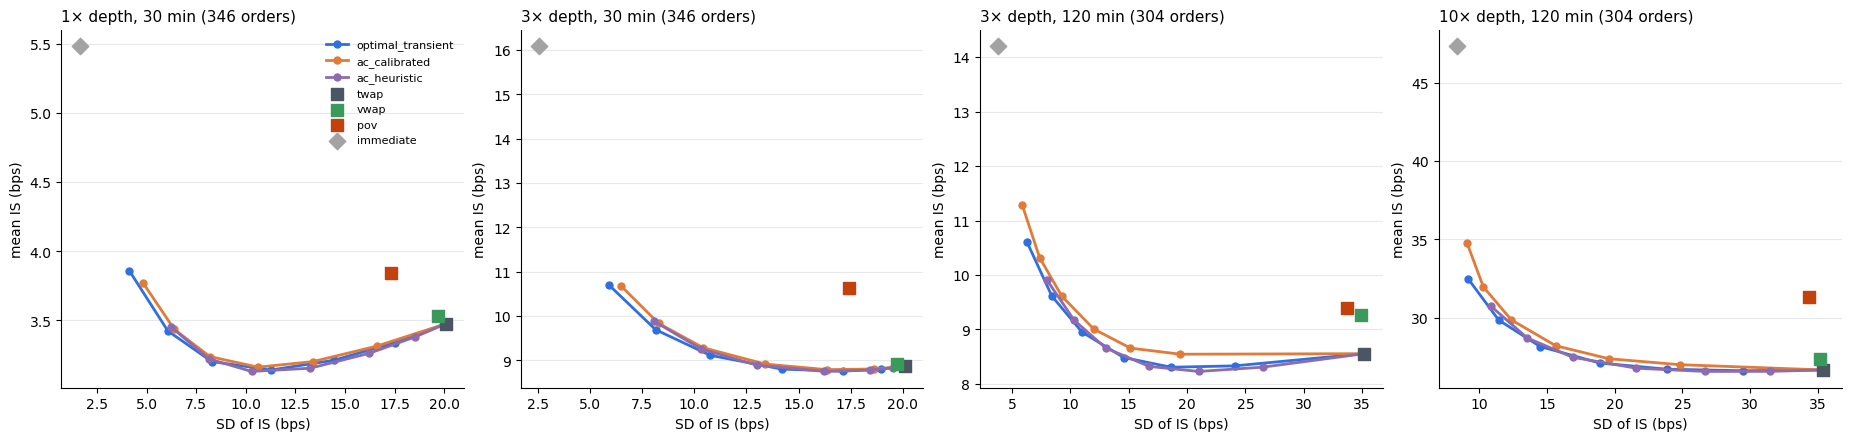

,size_mult,horizon_min,benchmark,orders,risk_at_bench_cost,bench_mean,bench_sd,cost_at_bench_risk,cost_saving_at_equal_risk_bps,risk_reduction_at_equal_cost_%
0,0.25,5,twap,352,8.33,0.64,9.35,NaN,NaN,10.98
1,0.25,5,vwap,352,8.33,0.64,9.35,NaN,NaN,10.98
2,0.25,5,pov,352,4.10,0.86,7.80,0.65,0.21,47.41
3,0.25,15,twap,346,14.48,1.02,15.03,NaN,NaN,3.61
4,0.25,15,vwap,346,NaN,1.05,14.88,1.02,0.03,NaN
5,0.25,15,pov,346,NaN,0.71,12.65,0.90,-0.19,NaN
6,0.25,30,twap,346,NaN,1.46,20.08,NaN,NaN,NaN
7,0.25,30,vwap,346,NaN,1.51,19.69,1.43,0.07,NaN
8,0.25,30,pov,346,16.81,1.26,17.34,1.29,-0.03,3.01
9,0.25,60,twap,332,NaN,1.67,26.86,NaN,NaN,NaN


In [27]:
def frontier(df):
    g = df.groupby(["strategy", "lambda"], dropna=False).IS_bps.agg(["mean", "std"]).reset_index()
    return g

def matched(df, fam, bench):
    fr = frontier(df); f = fr[fr.strategy == fam].sort_values("std")
    b = fr[(fr.strategy == bench)].iloc[0]
    out = {}
    if f["std"].min() <= b["std"] <= f["std"].max():
        out["cost_at_bench_risk"] = float(np.interp(b["std"], f["std"], f["mean"]))
    fm = f.sort_values("mean")
    if fm["mean"].min() <= b["mean"] <= fm["mean"].max():
        out["risk_at_bench_cost"] = float(np.interp(b["mean"], fm["mean"], fm["std"]))
    out.update({"bench_mean": b["mean"], "bench_sd": b["std"]})
    return out

head = []
for (k, T), g in base.groupby(["size_mult", "horizon_min"]):
    for bench in ("twap", "vwap", "pov"):
        mres = matched(g, "optimal_transient", bench)
        head.append({"size_mult": k, "horizon_min": T, "benchmark": bench, "orders": g.exec_id.nunique(), **mres})
HEAD = pd.DataFrame(head)
HEAD["cost_saving_at_equal_risk_bps"] = HEAD.bench_mean - HEAD.get("cost_at_bench_risk", np.nan)
HEAD["risk_reduction_at_equal_cost_%"] = 100 * (1 - HEAD.get("risk_at_bench_cost", np.nan) / HEAD.bench_sd)
HEAD.to_csv(A_DIR / "results_matched_risk.csv", index=False)

cells_show = sorted(base[["size_mult", "horizon_min"]].drop_duplicates().itertuples(index=False))
cells_show = [c for c in [(1.0, 30), (3.0, 30), (3.0, 120), (10.0, 120)] if tuple(c) in set(map(tuple, cells_show))] or cells_show[:4]
fig, ax = plt.subplots(1, len(cells_show), figsize=(4.6 * len(cells_show), 4.3), constrained_layout=True, squeeze=False); ax = ax[0]
for a_, (k, T) in zip(ax, cells_show):
    g = base[(base.size_mult == k) & (base.horizon_min == T)]; fr = frontier(g)
    for fam in ("optimal_transient", "ac_calibrated", "ac_heuristic"):
        f = fr[fr.strategy == fam].sort_values("lambda")
        a_.plot(f["std"], f["mean"], color=COL[fam], lw=2, marker="o", ms=5, label=fam)
    for b in ("twap", "vwap", "pov", "immediate"):
        f = fr[fr.strategy == b]
        if len(f): a_.scatter(f["std"], f["mean"], color=COL[b], s=70, zorder=3, label=b, marker="s" if b != "immediate" else "D")
    a_.set_xlabel("SD of IS (bps)"); a_.set_ylabel("mean IS (bps)")
    style(a_, f"{k:g}× depth, {T} min ({g.exec_id.nunique()} orders)")
ax[0].legend(frameon=False, fontsize=8)
fig.savefig(A_DIR / "realized_frontiers.png", dpi=120, bbox_inches="tight"); plt.show()
HEAD.round(2)

## 7 · By volatility regime (state known at the start of the order)

In [28]:
lab_opt = f"optimal_transient λ={REF_LAMBDA:g}"
reg = []
for rg, g in base.groupby("vol_regime_prev", observed=True):
    piv = g.pivot_table(index=["exec_id", "cluster"], columns="label", values="IS_bps").reset_index()
    for lab in ("vwap", "pov", f"ac_calibrated λ={REF_LAMBDA:g}", lab_opt):
        if lab not in piv: continue
        dlt = piv[lab] - piv["twap"]; lo, hi = boot_ci(dlt.values, piv.cluster.values)
        reg.append({"vol_regime_prev": rg, "strategy": lab, "orders": len(piv), "TWAP_SD": piv.twap.std(), "SD": piv[lab].std(),
                    "mean_minus_TWAP": dlt.mean(), "CI95": f"[{lo:.2f}, {hi:.2f}]"})
REG = pd.DataFrame(reg); REG.to_csv(A_DIR / "results_by_regime.csv", index=False)
REG.round(2)

,vol_regime_prev,strategy,orders,TWAP_SD,SD,mean_minus_TWAP,CI95
0,high,vwap,1152,38.28,38.12,0.40,"[-0.38, 1.30]"
1,high,pov,1152,38.28,30.68,1.97,"[-1.32, 5.35]"
2,high,ac_calibrated λ=0.01,1152,38.28,16.06,0.25,"[-7.85, 7.86]"
3,high,optimal_transient λ=0.01,1152,38.28,16.60,0.10,"[-7.64, 7.49]"
4,low,vwap,2620,19.47,19.57,0.30,"[0.09, 0.54]"
5,low,pov,2620,19.47,21.82,0.60,"[-0.73, 1.86]"
6,low,ac_calibrated λ=0.01,2620,19.47,10.98,0.99,"[-2.02, 3.52]"
7,low,optimal_transient λ=0.01,2620,19.47,10.79,0.64,"[-2.22, 3.16]"
8,normal,vwap,728,17.17,16.85,0.48,"[0.12, 0.98]"
9,normal,pov,728,17.17,23.75,1.30,"[-2.20, 4.60]"


## 8 · Robustness to the impact model
How the comparison changes when the simulator's impact is the optimizer's own model (`calib_kernel`, circular), the square-root law, or doubled.

In [29]:
rob = []
for scn, g in R.groupby("scenario"):
    t = table_vs(g)
    for lab in ("vwap", "pov", "immediate", f"ac_heuristic λ={REF_LAMBDA:g}", f"ac_calibrated λ={REF_LAMBDA:g}", lab_opt):
        if lab in t.index:
            rob.append({"scenario": scn, "strategy": lab, "mean_IS": t.loc[lab, "mean_IS_bps"], "SD_IS": t.loc[lab, "SD_IS_bps"],
                        "mean_minus_TWAP": t.loc[lab, "mean_minus_TWAP"], "CI95_lo": t.loc[lab, "CI95_lo"], "CI95_hi": t.loc[lab, "CI95_hi"]})
ROB = pd.DataFrame(rob); ROB.to_csv(A_DIR / "results_robustness.csv", index=False)
ROB.pivot_table(index="strategy", columns="scenario", values="mean_minus_TWAP").round(2)

scenario,calib_kernel,impact_x2,sqrt_law,test_day_kernel
strategy,,,,
ac_calibrated λ=0.01,-0.32,1.20,0.22,0.23
ac_heuristic λ=0.01,-0.51,0.24,-0.24,-0.23
immediate,3.80,8.64,5.09,4.97
optimal_transient λ=0.01,-0.42,0.64,-0.05,-0.04
pov,0.51,1.97,1.04,0.96
vwap,0.25,0.26,0.26,0.26


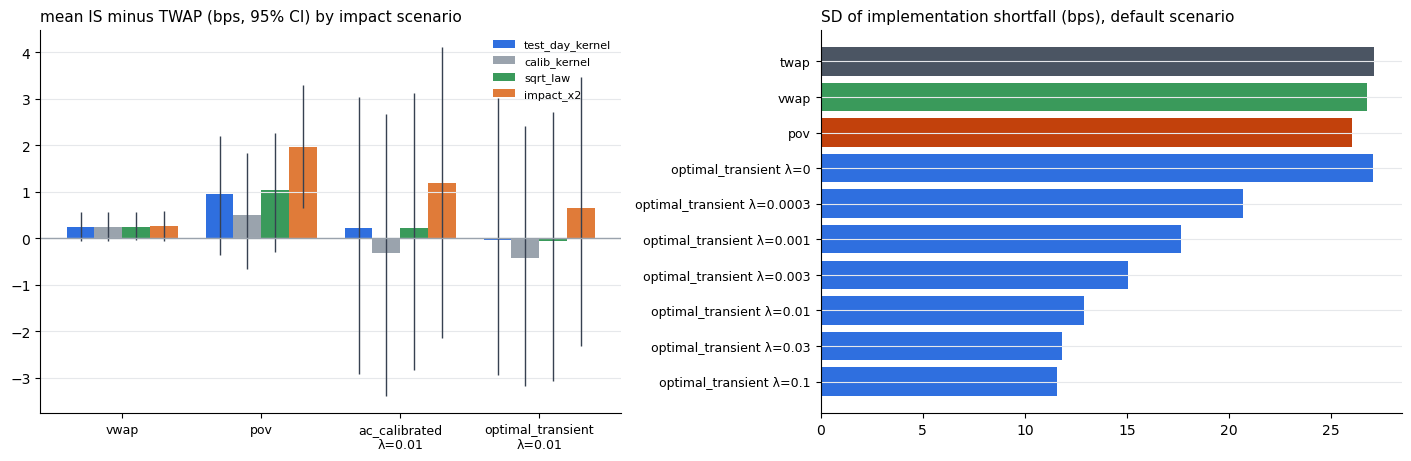

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
labs = ["vwap", "pov", f"ac_calibrated λ={REF_LAMBDA:g}", lab_opt]
x = np.arange(len(labs)); w = 0.8 / len(SCENARIOS)
for i, scn in enumerate(SCENARIOS):
    z = ROB[ROB.scenario == scn].set_index("strategy").reindex(labs)
    ax[0].bar(x + i * w, z.mean_minus_TWAP, w, label=scn, color=["#2f6fdf", "#9aa3ad", "#3a9a5b", "#e07b39"][i % 4])
    ax[0].errorbar(x + i * w, z.mean_minus_TWAP, yerr=[z.mean_minus_TWAP - z.CI95_lo, z.CI95_hi - z.mean_minus_TWAP], fmt="none", color="#374151", lw=1)
ax[0].axhline(0, color="#9aa3ad", lw=1); ax[0].set_xticks(x + w * (len(SCENARIOS) - 1) / 2, [l.replace(" λ=", "\nλ=") for l in labs], fontsize=9)
ax[0].legend(frameon=False, fontsize=8); style(ax[0], "mean IS minus TWAP (bps, 95% CI) by impact scenario")
t = OVERALL.reindex(["twap", "vwap", "pov"] + [f"optimal_transient λ={l:g}" for l in LAMBDAS_OOS])
ax[1].barh(np.arange(len(t)), t.SD_IS_bps, color=[COL.get(s.split(" ")[0], "#2f6fdf") for s in t.index])
ax[1].set_yticks(np.arange(len(t)), t.index, fontsize=9); ax[1].invert_yaxis(); style(ax[1], "SD of implementation shortfall (bps), default scenario")
fig.savefig(A_DIR / "backtest_summary.png", dpi=120, bbox_inches="tight"); plt.show()

## 9 · Summary

In [31]:
o = OVERALL
best_bench = o.loc[["vwap", "pov", "twap"]].SD_IS_bps.idxmin()
hb = HEAD[HEAD.benchmark == best_bench]
summary = {
    "orders_per_strategy": int(o.orders.max()), "test_days": TEST_DATES, "scenarios": list(SCENARIOS),
    "TWAP_mean_IS_bps": round(float(o.loc["twap", "mean_IS_bps"]), 3), "TWAP_SD_IS_bps": round(float(o.loc["twap", "SD_IS_bps"]), 2),
    f"OPT_{REF_LAMBDA}_mean_minus_TWAP_bps": round(float(o.loc[lab_opt, "mean_minus_TWAP"]), 3),
    f"OPT_{REF_LAMBDA}_CI95": [round(float(o.loc[lab_opt, "CI95_lo"]), 3), round(float(o.loc[lab_opt, "CI95_hi"]), 3)],
    f"OPT_{REF_LAMBDA}_SD_change_vs_TWAP_%": round(float(o.loc[lab_opt, "SD_minus_TWAP_%"]), 1),
    "lowest_risk_benchmark": best_bench,
    "median_cost_saving_at_equal_risk_vs_best_benchmark_bps": round(float(np.nanmedian(hb.cost_saving_at_equal_risk_bps)), 3) if hb.cost_saving_at_equal_risk_bps.notna().any() else None,
    "median_risk_reduction_at_equal_cost_vs_best_benchmark_%": round(float(np.nanmedian(hb["risk_reduction_at_equal_cost_%"])), 1) if hb["risk_reduction_at_equal_cost_%"].notna().any() else None,
}
json.dump(summary, open(A_DIR / "backtest_summary.json", "w"), indent=1, default=float)
for k_, v_ in summary.items(): print(f"{k_:58s} {v_}")

orders_per_strategy                                        4626
test_days                                                  ['2026-09-11', '2026-09-12', '2026-09-13', '2026-09-14']
scenarios                                                  ['test_day_kernel', 'calib_kernel', 'sqrt_law', 'impact_x2']
TWAP_mean_IS_bps                                           6.996
TWAP_SD_IS_bps                                             27.09
OPT_0.01_mean_minus_TWAP_bps                               -0.035
OPT_0.01_CI95                                              [-2.953, 2.719]
OPT_0.01_SD_change_vs_TWAP_%                               -52.4
lowest_risk_benchmark                                      pov
median_cost_saving_at_equal_risk_vs_best_benchmark_bps     0.291
median_risk_reduction_at_equal_cost_vs_best_benchmark_%    62.8


In [32]:
# ---- Diagnostic: where does the ~30 bps common noise come from? ----
b = R[(R.scenario == "test_day_kernel") & (R.strategy == "immediate")].copy()
print(b[["IS_bps", "drift_bps", "impact_bps", "walk_bps"]].describe(percentiles=[.01, .05, .5, .95, .99]).round(2))

rows = []
for d in TEST_DATES:
    mid, ok = DAYDATA[d]["mid"], DAYDATA[d]["ok"]
    idx = np.arange(86400)
    last_ok = pd.Series(np.where(ok, idx, np.nan)).ffill().values
    r1 = np.r_[np.nan, np.diff(np.log(mid))] * 1e4
    both_ok = ok & np.r_[False, ok[:-1]]
    big = np.flatnonzero(both_ok & (np.abs(r1) > 20))
    print(f"{d}: usable seconds {ok.mean():.1%} | 1-s mid jumps > 20 bps between usable seconds: {len(big)}",
          [f"{s//3600:02d}:{s%3600//60:02d}:{s%60:02d} ({r1[s]:+.0f})" for s in big[:8]])
    for _, w in b[b.test_date == d].iterrows():
        s = max(int(w.start_min * 60) - 1, 0); e = min(s + int(w.horizon_min * 60), 86399)
        rows.append({"test_date": d, "start": f"{int(w.start_min)//60:02d}:{int(w.start_min)%60:02d}",
                     "horizon_min": w.horizon_min, "drift_bps": w.drift_bps,
                     "arrival_usable": bool(ok[s]),
                     "arrival_stale_s": s - last_ok[s] if not np.isnan(last_ok[s]) else np.nan,
                     "unusable_s_in_window": int((~ok[s:e]).sum()),
                     "max_1s_jump_in_window": np.nanmax(np.abs(r1[s:e]))})
W = pd.DataFrame(rows)
bad = W.drift_bps.abs() > 15
print(f"\nimmediate orders with |drift| > 15 bps: {bad.sum()} of {len(W)}")
print(W.groupby(bad)[["arrival_usable", "arrival_stale_s", "unusable_s_in_window", "max_1s_jump_in_window"]].mean().round(2))
W.reindex(W.drift_bps.abs().sort_values(ascending=False).index).head(20)

        IS_bps  drift_bps  impact_bps  walk_bps
count  4626.00    4626.00     4626.00   4626.00
mean     11.97      -0.01        9.95      2.03
std      16.17       1.95       13.89      2.59
min     -22.12     -23.26        0.82      0.02
1%       -2.34      -5.66        0.82      0.02
5%       -0.16      -2.62        0.82      0.02
50%       5.29       0.00        3.74      1.05
95%      49.73       2.80       40.21      7.93
99%      61.76       5.20       54.65     11.65
max      70.22      13.82       54.65     20.76
2026-09-11: usable seconds 86.8% | 1-s mid jumps > 20 bps between usable seconds: 2 ['15:53:58 (-22)', '18:45:12 (+27)']
2026-09-12: usable seconds 99.3% | 1-s mid jumps > 20 bps between usable seconds: 0 []
2026-09-13: usable seconds 95.1% | 1-s mid jumps > 20 bps between usable seconds: 1 ['22:06:14 (-39)']
2026-09-14: usable seconds 91.0% | 1-s mid jumps > 20 bps between usable seconds: 1 ['20:12:26 (+24)']

immediate orders with |drift| > 15 bps: 8 of 4626
       

,test_date,start,horizon_min,drift_bps,arrival_usable,arrival_stale_s,unusable_s_in_window,max_1s_jump_in_window
663,2026-09-11,16:00,120,-23.255102,True,0.0,0,11.499171
664,2026-09-11,16:00,120,-23.255102,True,0.0,0,11.499171
666,2026-09-11,16:00,120,-23.255102,True,0.0,0,11.499171
665,2026-09-11,16:00,120,-23.255102,True,0.0,0,11.499171
819,2026-09-11,18:45,120,-17.863997,True,0.0,0,27.389956
817,2026-09-11,18:45,120,-17.863997,True,0.0,0,27.389956
818,2026-09-11,18:45,120,-17.863997,True,0.0,0,27.389956
820,2026-09-11,18:45,120,-17.863997,True,0.0,0,27.389956
1001,2026-09-11,22:00,120,13.818011,True,0.0,0,15.320898
1000,2026-09-11,22:00,120,13.818011,True,0.0,0,15.320898
